# Master Notebook — Credit Default Models
Each model lives in `models/` and exposes `run(data)` (training data only) and `report(res)` (cross-validated results).
All models share the same train/test split, 5-fold stratified CV and cost matrix (bad classed good = 5, good classed bad = 1).

**Workflow**
1. *Model development* — run, compare and iterate using **CV results only**.
2. *Final evaluation* — once every model is frozen, run that section **once**. Do not go back and tweak models after seeing test results.

To add a model: copy `models/template.py`, fill in `build()` and `GRID`, then add a cell below.

In [4]:
%matplotlib inline
from feature_engineering import get_data
from models import common

data = get_data()
results = {}
print({k: v.shape for k, v in data.items()})

{'X_train': (800, 21), 'X_test': (200, 21), 'y_train': (800,), 'y_test': (200,), 'groups_train': (800, 2), 'groups_test': (200, 2)}


# Part 1 — Model development (training data / CV only)

## Logistic Regression

Logistic Regression - CV out-of-fold (train)
Best params: {'clf__C': np.float64(0.1), 'clf__class_weight': None, 'clf__l1_ratio': 0.0}
CV AUC: 0.778 ± 0.054


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.776,0.588,0.644,0.392,0.487,0.182,0.978
t=0.18 (cost-opt),0.776,0.588,0.424,0.900,0.576,0.638,0.518


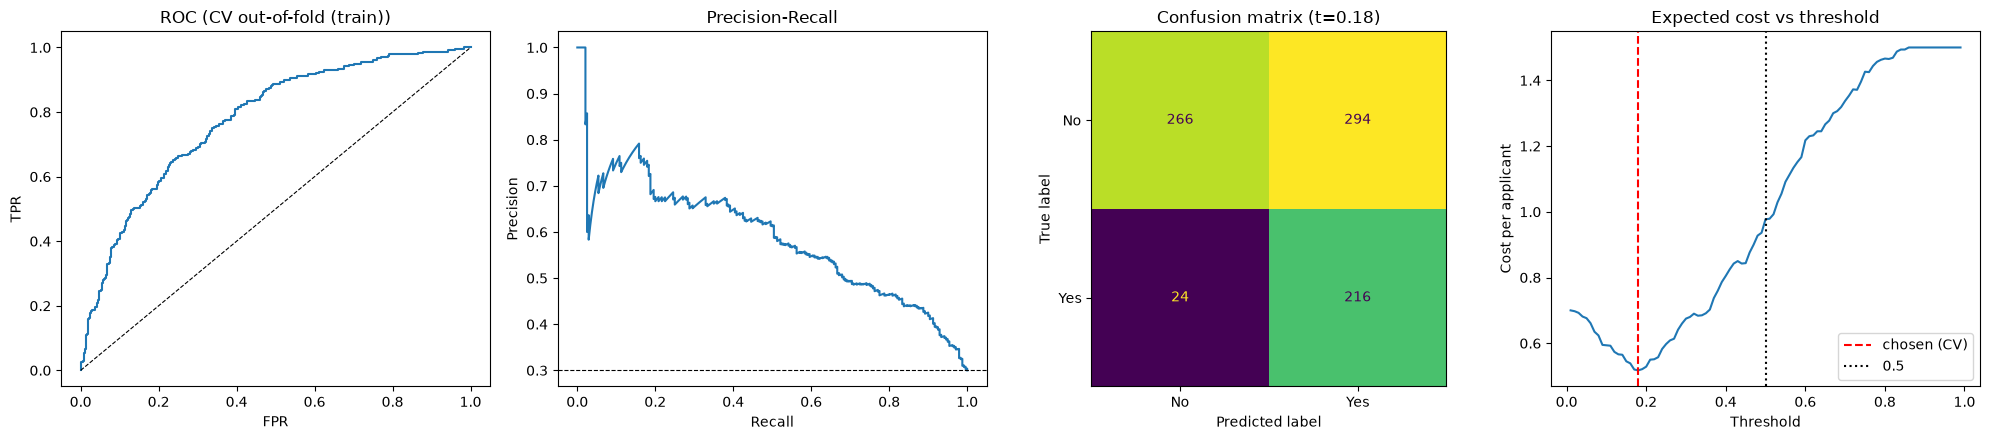

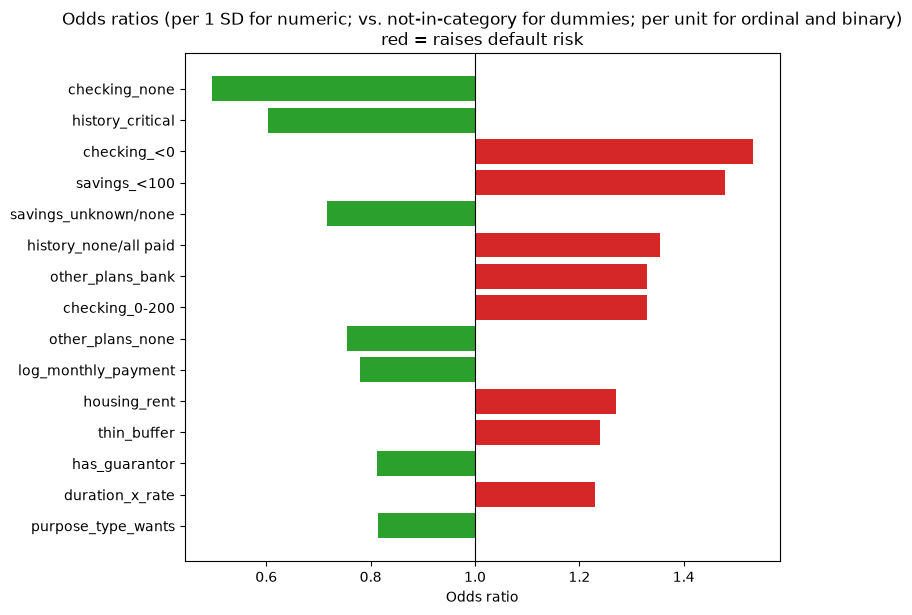

39 of 39 features kept (non-zero)


In [8]:
from models import logistic_regression as lr

results["lr"] = lr.run(data)
lr.report(results["lr"])

## Random Forest

In [ ]:
# from models import random_forest as rf
# results["rf"] = rf.run(data)
# rf.report(results["rf"])

## XGBoost

In [ ]:
from models import xgboost_model as xgbm

results["xgb"] = xgbm.run(data)
xgbm.report(results["xgb"])

## Model selection (CV)
Choose models on these cross-validated numbers, not on test results.

In [ ]:
common.compare(results.values(), on="cv")

# Part 2 — Final evaluation (run ONCE, after all models are frozen)
Everything below uses the held-out test set.

Logistic Regression - TEST SET
Best params: {'clf__C': np.float64(0.1), 'clf__class_weight': None, 'clf__l1_ratio': 0.0}
CV AUC: 0.778 ± 0.054


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.771,0.603,0.628,0.450,0.524,0.215,0.905
t=0.18 (cost-opt),0.771,0.603,0.400,0.867,0.547,0.650,0.590


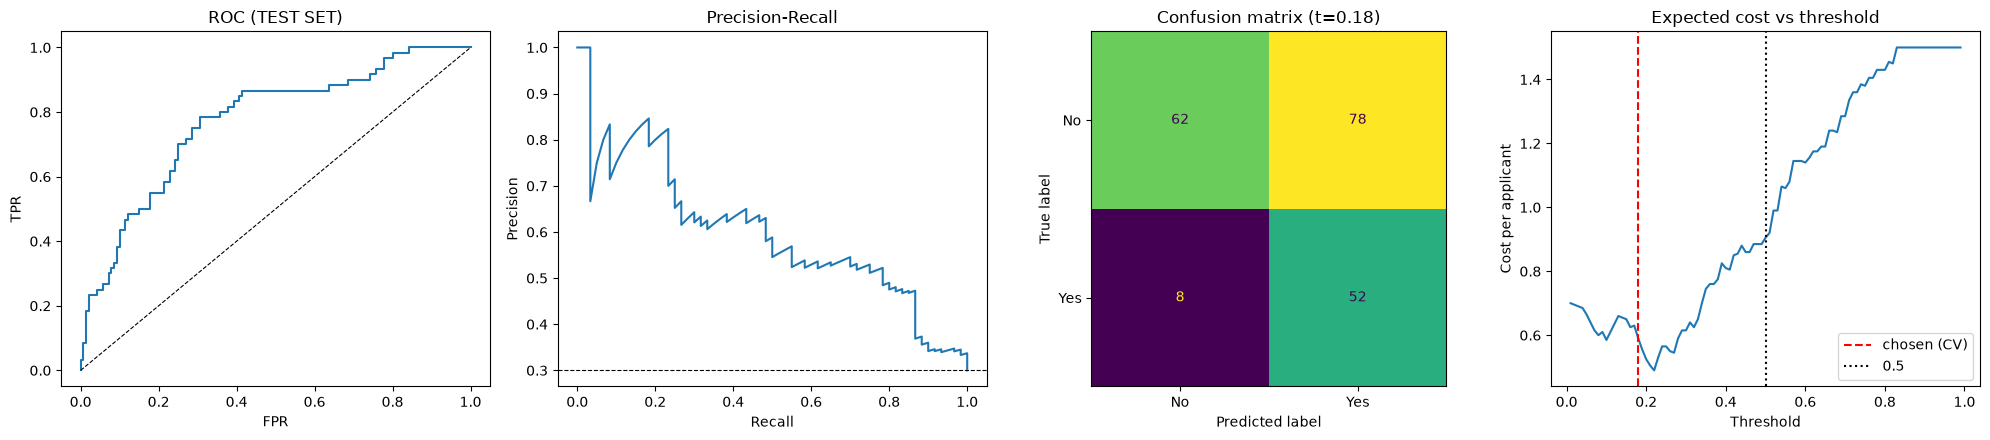

ANN - TEST SET
Best params: {'clf__activation': 'tanh', 'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (8, 4), 'clf__max_iter': 50}
CV AUC: 0.788 ± 0.050


,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
t=0.50,0.796,0.66,0.612,0.500,0.550,0.245,0.845
t=0.14 (cost-opt),0.796,0.66,0.445,0.883,0.592,0.595,0.505


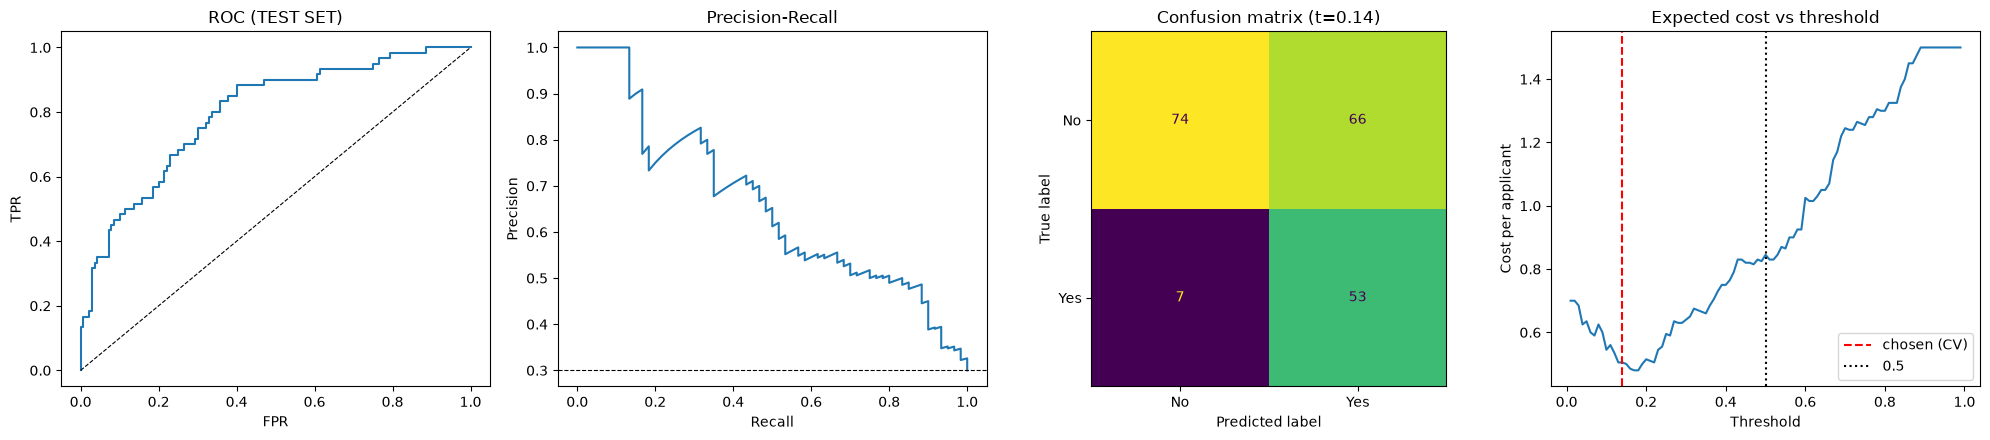

TEST SET


,cv_auc,cv_auc_std,threshold,auc,avg_precision,precision,recall,f1,reject_rate,cost_per_applicant
Logistic Regression,0.778,0.054,0.18,0.771,0.603,0.400,0.867,0.547,0.650,0.590
ANN,0.788,0.050,0.14,0.796,0.660,0.445,0.883,0.592,0.595,0.505
Approve all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,1.500
Reject all,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.700


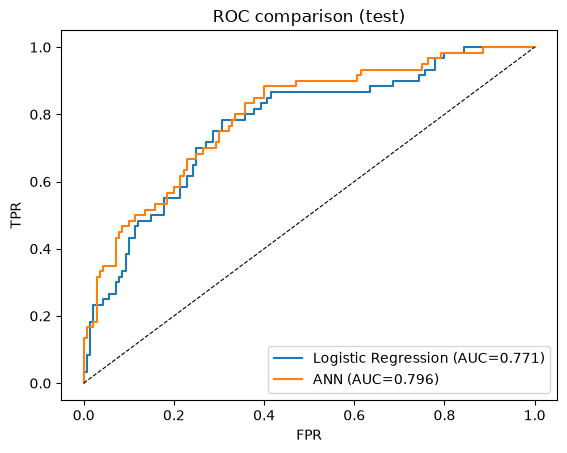

In [6]:
for res in results.values():
    common.evaluate(res, data)
    common.report(res, on="test")

common.compare(results.values(), on="test")

## Explainability (SHAP)

Background dataset has 800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=800 when initializing the masker.


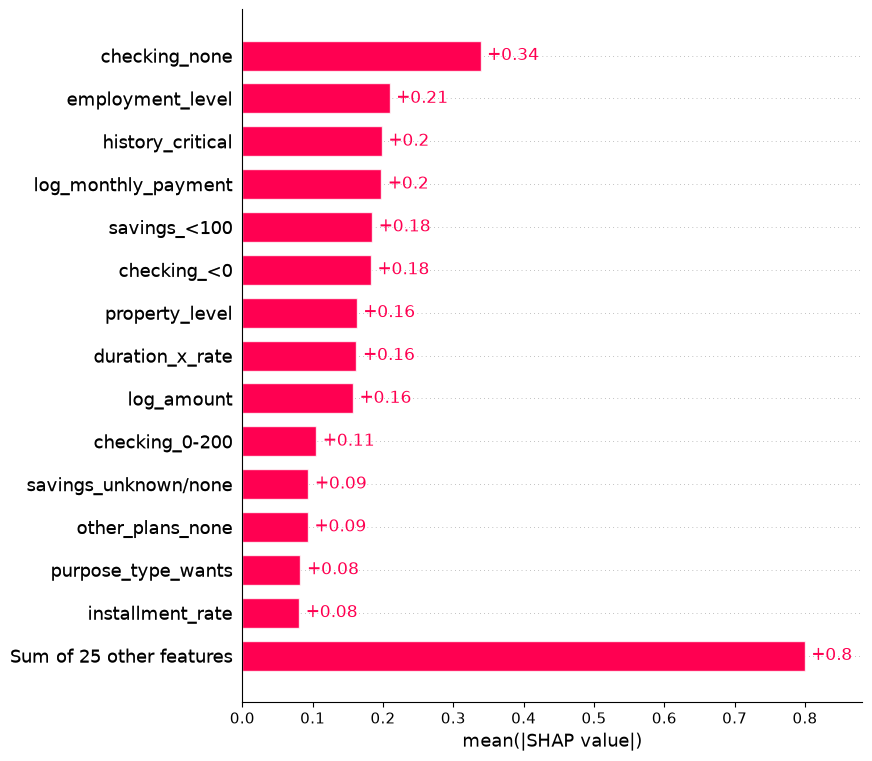

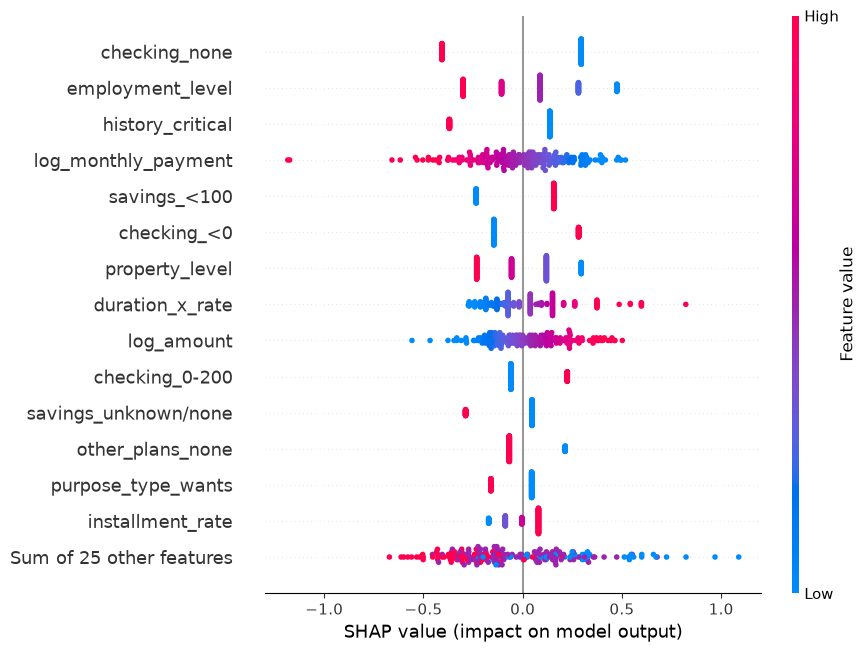

Highest-risk test applicant: P(default) = 0.83


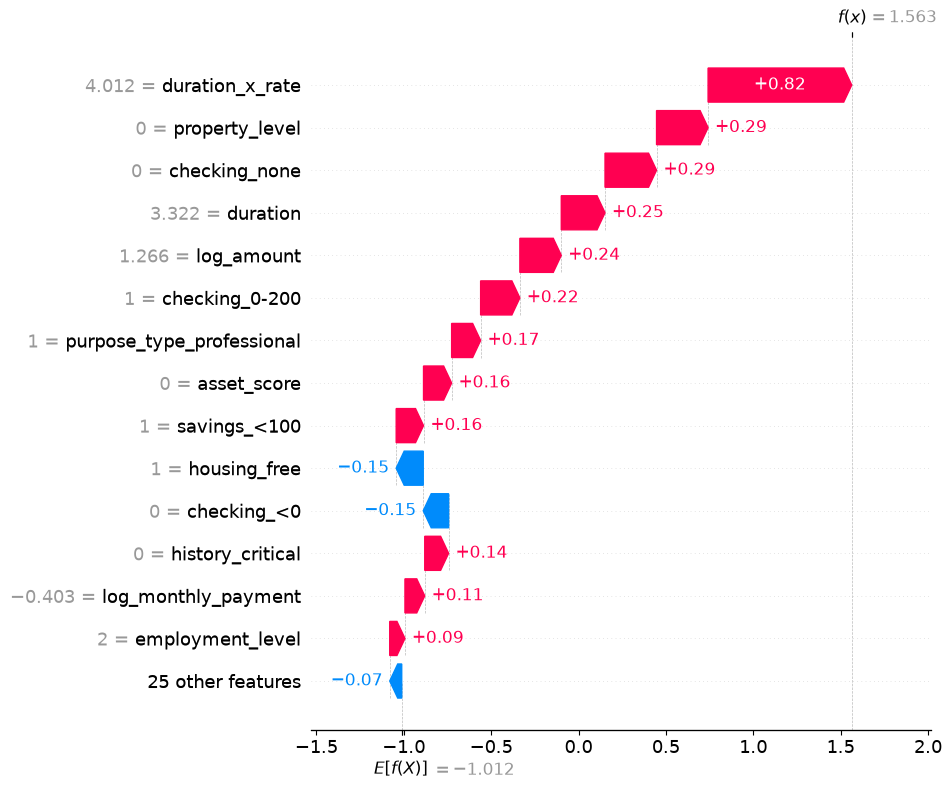

In [7]:
sv = common.explain(results["lr"], data)

## Fairness analysis

In [ ]:
fair = common.fairness(results["lr"], data)